---
title: "Self-study Lab 5: Gradient Descent, Normal Equation and scikit-learn"
subtitle: "Machine Learning, Lecture 3: Multiple linear regression"
author: "Khiem Nguyen"
format:
  html:
    toc: true
    toc-depth: 3
    embed-resources: true
    code-overflow: wrap
    fig-align: center
jupyter: python3
---

## Objectives

In this self-study lab you will

- solve the normal equation for the lecture's worked example with NumPy;
- fold the bias $b$ into the parameter vector by adding a column of ones;
- compare the normal equation, gradient descent and scikit-learn;
- see when the normal equation has no unique solution;
- evaluate models with MSE, RMSE and $R^2$, on training and test data;
- create polynomial features and fit a polynomial regression with a scikit-learn pipeline.

## Tools

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, root_mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

np.set_printoptions(precision=3, suppress=True)   # print arrays with 3 decimals, no e-notation

`root_mean_squared_error` requires scikit-learn 1.4 or newer.

## The normal equation: a worked example

We use the data from the lecture: $(x, y) \in \{(1, 300),\ (2, 450),\ (3, 500)\}$.

### Folding $b$ into the parameter vector

Adding a constant feature $x_0 = 1$ and calling the bias $w_0 = b$ turns the model into a single dot product, $f(\mathbf x) = \boldsymbol\theta\cdot\tilde{\mathbf x}$ with $\boldsymbol\theta = (b, w_1, \dots, w_n)$ and $\tilde{\mathbf x} = (1, x_1, \dots, x_n)$. For the whole data set we add a column of ones to the design matrix: $\tilde{\mathbf X} = [\,\mathbf 1\ \ \mathbf X\,]$.

In [2]:
x = np.array([1.0, 2.0, 3.0])
y = np.array([300.0, 450.0, 500.0])

X_tilde = np.column_stack([np.ones_like(x), x])   # shape (m, 2): [1, x]
print(X_tilde)

[[1. 1.]
 [1. 2.]
 [1. 3.]]


### Solving the normal equation

At the minimum of $J$ the gradient vanishes, which gives the normal equation
$$
\tilde{\mathbf X}^{\top}\tilde{\mathbf X}\,\boldsymbol\theta = \tilde{\mathbf X}^{\top}\mathbf y .
$$
This is a linear system $\mathbf A\boldsymbol\theta = \mathbf r$ with $\mathbf A = \tilde{\mathbf X}^{\top}\tilde{\mathbf X}$ and $\mathbf r = \tilde{\mathbf X}^{\top}\mathbf y$.

In [3]:
A = X_tilde.T @ X_tilde
r = X_tilde.T @ y
print(f"A =\n{A}\nr = {r}")

theta = np.linalg.solve(A, r)
b_ne, w_ne = theta
print(f"normal equation: b = {b_ne:.2f}, w = {w_ne:.2f}")

A =
[[ 3.  6.]
 [ 6. 14.]]
r = [1250. 2700.]
normal equation: b = 216.67, w = 100.00


We get $\mathbf A$, $\mathbf r$ and $\boldsymbol\theta = (216.67, 100)$ exactly as in the lecture.

::: {.callout-tip title="Solve, do not invert"}
The formula $\boldsymbol\theta = (\tilde{\mathbf X}^{\top}\tilde{\mathbf X})^{-1}\tilde{\mathbf X}^{\top}\mathbf y$ is useful on paper, but in code use `np.linalg.solve(A, r)` instead of `np.linalg.inv(A) @ r`. Solving the system directly is faster and more accurate than computing the inverse first.
:::

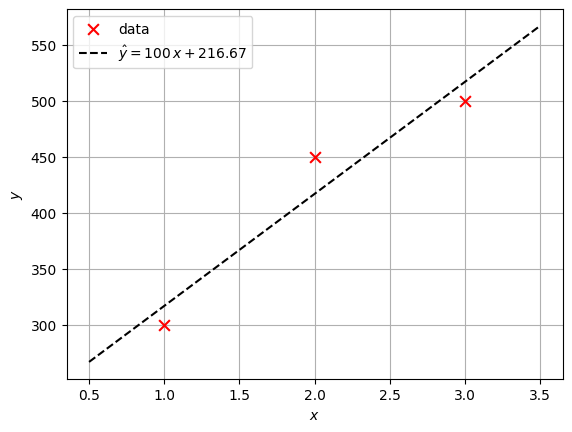

In [4]:
x_line = np.array([0.5, 3.5])
plt.scatter(x, y, marker='x', c='r', s=60, zorder=3, label='data')
plt.plot(x_line, w_ne * x_line + b_ne, 'k--', label=f'$\\hat{{y}} = {w_ne:.0f}\\,x + {b_ne:.2f}$')
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.legend()
plt.grid(True)
plt.show()

### The same fit with scikit-learn

`LinearRegression` solves the same least-squares problem directly, so it must give the same parameters. Remember that scikit-learn expects a 2D array of features.

In [5]:
model = LinearRegression()
model.fit(x.reshape(-1, 1), y)
print(f"scikit-learn:    b = {model.intercept_:.2f}, w = {model.coef_[0]:.2f}")

scikit-learn:    b = 216.67, w = 100.00


### The same fit with gradient descent

We use the vectorised `gradient_descent` from the lecture (and Lab 3), which starts from $\mathbf w = \mathbf 0$, $b = 0$.

In [6]:
def gradient_descent(X, y, alpha=0.1, n_iters=1000):
    """Batch gradient descent from w = 0, b = 0; returns w, b and the cost history."""
    m, n = X.shape
    w, b = np.zeros(n), 0.0
    J_history = np.zeros(n_iters)
    for t in range(n_iters):
        err = X @ w + b - y
        J_history[t] = np.sum(err ** 2) / (2 * m)
        w, b = w - alpha * (X.T @ err) / m, b - alpha * np.sum(err) / m
    return w, b, J_history

for n_iters in [100, 1000]:
    w_gd, b_gd, _ = gradient_descent(x.reshape(-1, 1), y, alpha=0.3, n_iters=n_iters)
    print(f"gradient descent, {n_iters:4d} iterations: b = {b_gd:.2f}, w = {w_gd[0]:.2f}")

gradient descent,  100 iterations: b = 212.99, w = 101.62
gradient descent, 1000 iterations: b = 216.67, w = 100.00


The inputs $x = 1, 2, 3$ are those of the toy data in Lab 2, so the cost has the same long, narrow valley: $\alpha$ must be below about $0.36$, and convergence along the valley takes several hundred iterations. After $1000$ iterations all three methods agree.

## Comparing the methods on the diabetes data

For the diabetes data with all ten features, the normal equation needs **no feature scaling**: we can solve it on the raw features directly.

In [7]:
diabetes = load_diabetes(scaled=False)
X, y_d = diabetes.data, diabetes.target

X_tilde = np.column_stack([np.ones(X.shape[0]), X])     # shape (442, 11)
theta = np.linalg.solve(X_tilde.T @ X_tilde, X_tilde.T @ y_d)

model = LinearRegression().fit(X, y_d)
theta_sk = np.concatenate([[model.intercept_], model.coef_])
print(f"largest difference between the parameters: {np.max(np.abs(theta - theta_sk)):.1e}")

largest difference between the parameters: 4.8e-10


The two solutions agree up to round-off. Gradient descent reaches the same parameters too, but in a reasonable number of iterations only after feature scaling (Lab 4). In short:

| | gradient descent | normal equation |
|:--|:--|:--|
| learning rate, iterations | needed | not needed |
| feature scaling | needed in practice | not needed |
| large number of features $n$ | works well | slow: solving the system costs about $n^3$ operations |
| other models (logistic regression, neural networks) | works | does not apply |

## When the normal equation has no unique solution

$\tilde{\mathbf X}^{\top}\tilde{\mathbf X}$ is invertible exactly when the columns of $\tilde{\mathbf X}$ are linearly independent. This fails if a feature is a linear combination of others (for example the floor area in m² and in ft²), or if there are fewer examples than parameters, $m < n + 1$.

The following toy data set, from an earlier version of this lab, has $m = 3$ houses but $n = 4$ features (size in ft², bedrooms, floors, age), i.e. five parameters.

In [8]:
X_house = np.array([[600, 2, 1, 45], [480, 1, 1, 40], [750, 3, 2, 35]], dtype=float)
y_house = np.array([150.0, 110.0, 190.0])

X_tilde_h = np.column_stack([np.ones(3), X_house])
A_h = X_tilde_h.T @ X_tilde_h
print(f"A has shape {A_h.shape} but rank {np.linalg.matrix_rank(A_h)}: it is singular.")

A has shape (5, 5) but rank 3: it is singular.


Five unknowns and only three equations: infinitely many parameter vectors fit the three houses **exactly**. Different methods return different ones, all with cost $J = 0$:

In [9]:
model_h = LinearRegression().fit(X_house, y_house)
theta_sk = np.concatenate([[model_h.intercept_], model_h.coef_])
theta_ls, *_ = np.linalg.lstsq(X_tilde_h, y_house, rcond=None)      # another least-squares solver

for name, th in [("scikit-learn", theta_sk), ("np.linalg.lstsq", theta_ls)]:
    J = np.mean((X_tilde_h @ th - y_house) ** 2) / 2
    print(f"{name:16s} theta = {th}, J = {J:.1e}")

scikit-learn     theta = [-62.186   0.308   0.012  -0.037   0.613], J = 0.0e+00
np.linalg.lstsq  theta = [-3.684  0.235 12.185 -8.212 -0.077], J = 1.4e-27


With such data, gradient descent and scikit-learn can disagree even after full convergence. Neither answer is wrong, but none of them is a trustworthy model: we need (many) more examples than parameters.

## Evaluating a regression model

### MSE, RMSE and $R^2$

From the lecture:
$$
\mathrm{MSE} = \frac1m\sum_{i=1}^{m}\big(y^{(i)} - \hat y^{(i)}\big)^2,
\qquad
\mathrm{RMSE} = \sqrt{\mathrm{MSE}},
\qquad
R^2 = 1 - \frac{\sum_i \big(y^{(i)} - \hat y^{(i)}\big)^2}{\sum_i \big(y^{(i)} - \bar y\big)^2}.
$$
The RMSE has the same units as $y$. $R^2$ is the fraction of the variation of $y$ that the model explains: $R^2 = 1$ for perfect predictions, $R^2 = 0$ for the baseline that always predicts the mean $\bar y$, and $R^2 < 0$ for a model worse than that baseline.

In [10]:
def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - ss_res / ss_tot

y_pred = w_ne * x + b_ne          # predictions for the worked example
print(f"our functions: MSE = {mse(y, y_pred):.2f}, RMSE = {np.sqrt(mse(y, y_pred)):.2f}, "
      f"R2 = {r2(y, y_pred):.4f}")
print(f"scikit-learn:  MSE = {mean_squared_error(y, y_pred):.2f}, "
      f"RMSE = {root_mean_squared_error(y, y_pred):.2f}, R2 = {r2_score(y, y_pred):.4f}")

our functions: MSE = 555.56, RMSE = 23.57, R2 = 0.9231
scikit-learn:  MSE = 555.56, RMSE = 23.57, R2 = 0.9231


Note the order of the arguments in scikit-learn: first the true values, then the predictions. A fitted model also has `model.score(X, y)`, which returns $R^2$.

### Training and test data

A model should be judged on data it has not seen during training. We hold back $20\%$ of the patients as a **test set**, fit on the remaining $80\%$, and compare the model with all ten features to the model with BMI alone.

In [11]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y_d, test_size=0.2, random_state=1)
bmi = diabetes.feature_names.index('bmi')

for name, cols in [("BMI only", [bmi]), ("all ten features", list(range(10)))]:
    model = LinearRegression().fit(X_tr[:, cols], y_tr)
    r2_train = model.score(X_tr[:, cols], y_tr)
    r2_test = model.score(X_te[:, cols], y_te)
    rmse_test = root_mean_squared_error(y_te, model.predict(X_te[:, cols]))
    print(f"{name:17s}: R2 train = {r2_train:.3f}, R2 test = {r2_test:.3f}, RMSE test = {rmse_test:.1f}")

BMI only         : R2 train = 0.363, R2 test = 0.251, RMSE test = 63.2
all ten features : R2 train = 0.533, R2 test = 0.438, RMSE test = 54.7


More features explain more of the variation, but even all ten features explain only about half of it: disease progression depends on much more than these measurements. The test scores are lower than the training scores, as is typical: the model is fitted to the training data, so it does a little worse on new patients. Only the test score is an honest estimate of the performance on new data.

## Polynomial regression

### Polynomial features

`PolynomialFeatures` creates the new features $x, x^2, x^3, \dots$ from a single input $x$. With `include_bias=True` it also adds the column of ones $x_0 = 1$, which we do not need when the model has its own bias $b$ (as `LinearRegression` does).

In [12]:
x_col = np.array([[1.0], [2.0], [3.0]])           # shape (3, 1)
print(PolynomialFeatures(degree=3, include_bias=False).fit_transform(x_col))
print(PolynomialFeatures(degree=3, include_bias=True).fit_transform(x_col))

[[ 1.  1.  1.]
 [ 2.  4.  8.]
 [ 3.  9. 27.]]
[[ 1.  1.  1.  1.]
 [ 1.  2.  4.  8.]
 [ 1.  3.  9. 27.]]


### Fitting curves with a pipeline

We generate data that bend: they rise steeply, flatten and rise again. A polynomial model $f_{\mathbf w,b}(x) = w_1x + w_2x^2 + \dots + w_dx^d + b$ is still **linear in the parameters**, so it is fitted by ordinary linear regression on the features $x, x^2, \dots, x^d$. Since $x$ goes up to 10, $x^3$ goes up to 1000, so feature scaling is important. A **pipeline** chains the three steps and applies the same steps, with the same training statistics, when predicting.

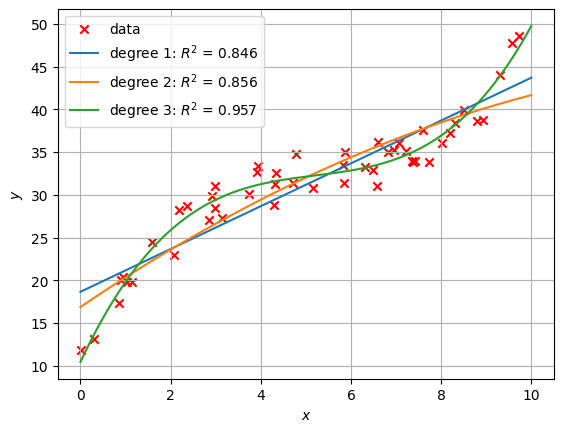

In [13]:
rng = np.random.default_rng(3)
x_p = np.sort(rng.uniform(0, 10, 50))
y_p = 10 + 12 * x_p - 2.2 * x_p**2 + 0.14 * x_p**3 + rng.normal(0, 1.5, 50)
X_p = x_p.reshape(-1, 1)
x_plot = np.linspace(0, 10, 200).reshape(-1, 1)

plt.scatter(x_p, y_p, marker='x', c='r', label='data')
for degree in [1, 2, 3]:
    poly_model = make_pipeline(PolynomialFeatures(degree=degree, include_bias=False),
                               StandardScaler(),
                               LinearRegression())
    poly_model.fit(X_p, y_p)
    r2_poly = poly_model.score(X_p, y_p)
    plt.plot(x_plot, poly_model.predict(x_plot), label=f'degree {degree}: $R^2$ = {r2_poly:.3f}')
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.legend()
plt.grid(True)
plt.show()

The data have an S-shaped bend: a steep start, a flat middle part and a rise at the end. The straight line and the concave quadratic miss it at both ends, while the cubic follows the data well. A higher degree is not always better, though: a very flexible model starts to fit the noise instead of the trend (**overfitting**, Lecture 5).

## Challenges

1. Solve the normal equation for the worked example by hand, using $(\tilde{\mathbf X}^{\top}\tilde{\mathbf X})^{-1} = \begin{pmatrix}7/3 & -1\\ -1 & 1/2\end{pmatrix}$, and check the result against the code.
2. Add a column `2 * X[:, 2]` (twice the BMI) to the diabetes features and compute the rank of $\tilde{\mathbf X}^{\top}\tilde{\mathbf X}$. What does scikit-learn return now? Are its predictions still good?
3. Fit the polynomial data with degree $10$ and $15$. How do $R^2$ and the curve change? Would you trust these models between and beyond the data points?

## Summary

- Normal equation: $\tilde{\mathbf X}^{\top}\tilde{\mathbf X}\boldsymbol\theta = \tilde{\mathbf X}^{\top}\mathbf y$ with a column of ones in $\tilde{\mathbf X}$; in code use `np.linalg.solve`.
- The normal equation, scikit-learn and (converged) gradient descent give the same parameters; only the normal equation and scikit-learn do not need feature scaling.
- If $\tilde{\mathbf X}^{\top}\tilde{\mathbf X}$ is singular (dependent features, or $m < n + 1$), there are infinitely many best fits.
- Evaluate with MSE, RMSE and $R^2$, and judge a model on test data it has not seen.
- Polynomial regression is linear regression on the features $x, x^2, \dots$; use a pipeline with feature scaling.